# SafeRoute AI — Experiment: Accident Severity Classification

**ICT605 – Interactive Data Visualisation and Simulation**

This notebook provides the reproducible Python/ML feasibility evidence for SafeRoute AI. It covers dataset loading and quality checks, exploratory analysis, feature engineering, preprocessing, a majority-class baseline, Random Forest class-weight experiments, validation-based model selection, final test evaluation, error analysis, a sample scenario prediction, prediction probabilities, and model feature importance.

**Target:** `Severity` (1–4), representing the effect of an accident on traffic flow,severity.

**Dataset sample:** 500,000 accident records.

**Modelling features:** 37 input features after feature engineering and selection.


## 1. Environment and imports

The notebook uses standard Python data-science and scikit-learn libraries.

In [ ]:
#STEP 1—IMPORT LIBRARIES
import os
import platform
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Platform:", platform.platform())
print("Libraries imported successfully.")

Python: 3.13.18
Pandas: 2.2.3
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Libraries imported successfully.


## 2. Load the 500,000-record sample

The notebook first checks common locations so it can run either from the submitted evidence folder or in Google Colab after the CSV has been uploaded.

In [ ]:
#STEP 2–LOAD DATASET

file_path = "/content/US_Accidents_March23_sampled_500k.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (500000, 46)


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,Accident on LA-19 Baker-Zachary Hwy at Lower Z...,Highway 19,Zachary,East Baton Rouge,LA,70791-4610,US,US/Central,KBTR,2019-06-12 09:53:00,77.0,77.0,62.0,29.92,10.0,NW,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,Incident on FOREST RIDGE DR near PEPPERIDGE PL...,Forest Ridge Dr,Sterling,Loudoun,VA,20164-2813,US,US/Eastern,KIAD,2022-12-03 23:52:00,45.0,43.0,48.0,29.91,10.0,W,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,Accident on W Central Ave from Floradale Ave t...,Floradale Ave,Lompoc,Santa Barbara,CA,93436,US,US/Pacific,KLPC,2022-08-20 12:56:00,68.0,68.0,73.0,29.79,10.0,W,13.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,Incident on I-90 EB near REST AREA Drive with ...,14th St NW,Austin,Mower,MN,55912,US,US/Central,KAUM,2022-02-21 17:35:00,27.0,15.0,86.0,28.49,10.0,ENE,15.0,0.0,Wintry Mix,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,RP ADV THEY LOCATED SUSP VEH OF 20002 - 726 CR...,River Blvd,Bakersfield,Kern,CA,93305-2649,US,US/Pacific,KBFL,2020-12-04 01:54:00,42.0,42.0,34.0,29.77,10.0,CALM,0.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night


## 3. Dataset readiness and data-quality checks

In [ ]:
#STEP 3—DATASET OVERVIEW AND QUALITY CHECKS
print("Rows:",len(df))
print("Columns:",len(df.columns))
print("Duplicate rows:",df.duplicated().sum())

print("\nTarget present:","Severity" in df.columns)
print("Target missing values:",df["Severity"].isna().sum())

missing_summary=(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)
missing_summary["Missing %"]=(missing_summary["Missing Values"]/len(df)*100).round(2)
display(missing_summary.head(15))

print("\nData types:")
display(df.dtypes.to_frame("dtype").head(20))

Rows: 500000
Columns: 46
Duplicate rows: 0

Target present: True
Target missing values: 0


,Missing Values,Missing %
End_Lng,220377,44.08
End_Lat,220377,44.08
Precipitation(in),142616,28.52
Wind_Chill(F),129017,25.80
Wind_Speed(mph),36987,7.40
Visibility(mi),11291,2.26
Wind_Direction,11197,2.24
Humidity(%),11130,2.23
Weather_Condition,11101,2.22
Temperature(F),10466,2.09



Data types:


,dtype
ID,object
Source,object
Severity,int64
Start_Time,object
End_Time,object
Start_Lat,float64
Start_Lng,float64
End_Lat,float64
End_Lng,float64
Distance(mi),float64


## 4. Exploratory data analysis

These lightweight charts establish that the target is highly imbalanced and show useful temporal/environmental patterns before modelling.

Severity distribution:


,Count,Percentage
Severity,,
1,4274,0.85
2,398142,79.63
3,84520,16.90
4,13064,2.61


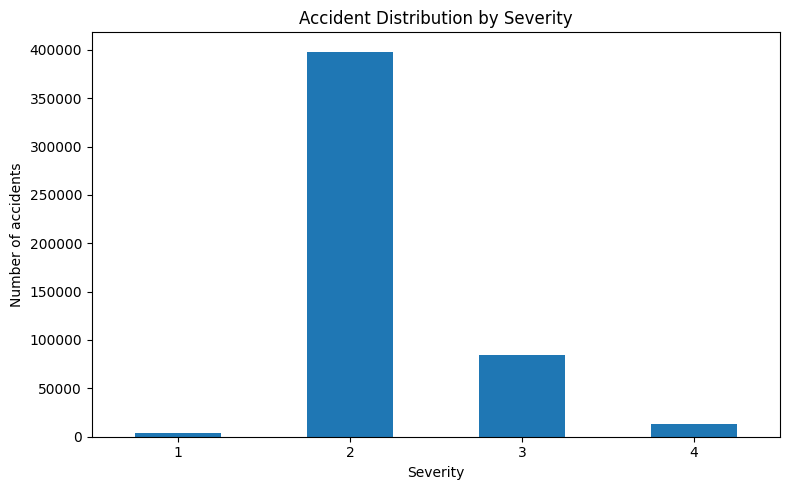

In [ ]:
#STEP 4—SEVERITY DISTRIBUTION
severity_counts=df["Severity"].value_counts().sort_index()
severity_percentage=(df["Severity"].value_counts(normalize=True).sort_index()*100)

severity_table=pd.DataFrame({
    "Count":severity_counts,
    "Percentage":severity_percentage.round(2)
})

print("Severity distribution:")
display(severity_table)

severity_counts.plot(kind="bar",figsize=(8, 5))
plt.title("Accident Distribution by Severity")
plt.xlabel("Severity")
plt.ylabel("Number of accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#STEP 5 — CONVERT START TIME AND CREATE TIME FEATURES
df["Start_Time"]=pd.to_datetime(df["Start_Time"], errors="coerce")
df["Hour"]=df["Start_Time"].dt.hour
df["DayOfWeek"]=df["Start_Time"].dt.dayofweek
df["Month"]=df["Start_Time"].dt.month
df["Year"]=df["Start_Time"].dt.year
df["Weekend"]=(df["DayOfWeek"] >= 5).astype(int)

print("Start_Time conversion and basic time features completed.")
print("Unparsed Start_Time values:",df["Start_Time"].isna().sum())

Start_Time conversion and basic time features completed.
Unparsed Start_Time values: 48163


,Accidents
TimeOfDay,
Morning,171247
Afternoon,132109
Evening,88816
Night,59665


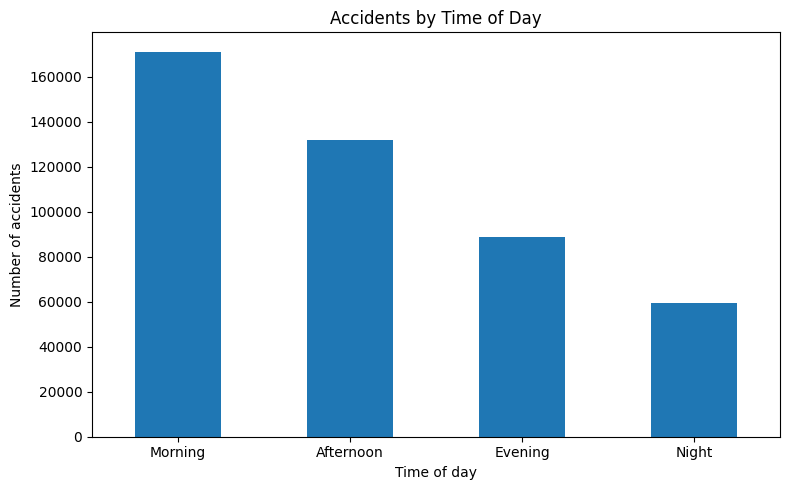

In [ ]:
#STEP 6 — TIME-OF-DAY EXPLORATION
def get_time_of_day(hour):
    if pd.isna(hour):
        return np.nan
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["TimeOfDay"]=df["Hour"].apply(get_time_of_day)
time_of_day_counts=df["TimeOfDay"].value_counts().reindex(
    ["Morning", "Afternoon", "Evening", "Night"]
).dropna()

display(time_of_day_counts.to_frame("Accidents"))

time_of_day_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Accidents by Time of Day")
plt.xlabel("Time of day")
plt.ylabel("Number of accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

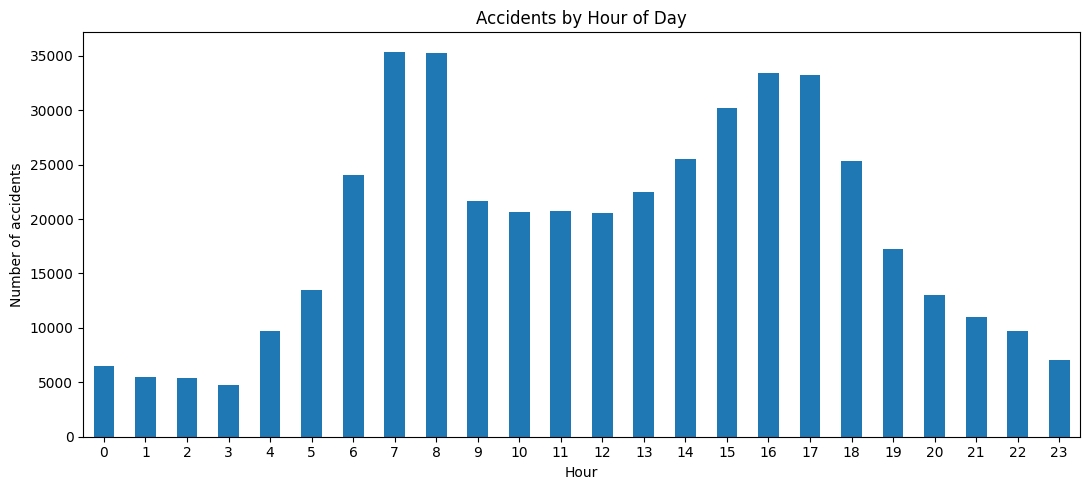

In [ ]:
#STEP 7 — HOURLY ACCIDENT PATTERN
hour_counts = df["Hour"].value_counts().sort_index()
hour_counts.plot(kind="bar", figsize=(11, 5))
plt.title("Accidents by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of accidents")
plt.xticks(range(24), range(24), rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#STEP 8 — CREATE RUSH HOUR AND SEASON
df["RushHour"] = (
    df["Hour"].between(7, 9) | df["Hour"].between(16, 19)
).astype(int)
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"
    return np.nan

df["Season"] = df["Month"].apply(get_season)
print("Rush hour counts:")
display(df["RushHour"].value_counts().sort_index().rename("Accidents").to_frame())
print("Season counts:")
display(df["Season"].value_counts().reindex(["Winter", "Spring", "Summer", "Autumn"]).rename("Accidents").to_frame())

Rush hour counts:


,Accidents
RushHour,
0,298442
1,201558


Season counts:


,Accidents
Season,
Winter,129205
Spring,99190
Summer,99260
Autumn,124182


,Accidents / records flagged
Rush Hour,201558
Poor Weather,56402
Low Visibility,40255
Freezing Condition,39673


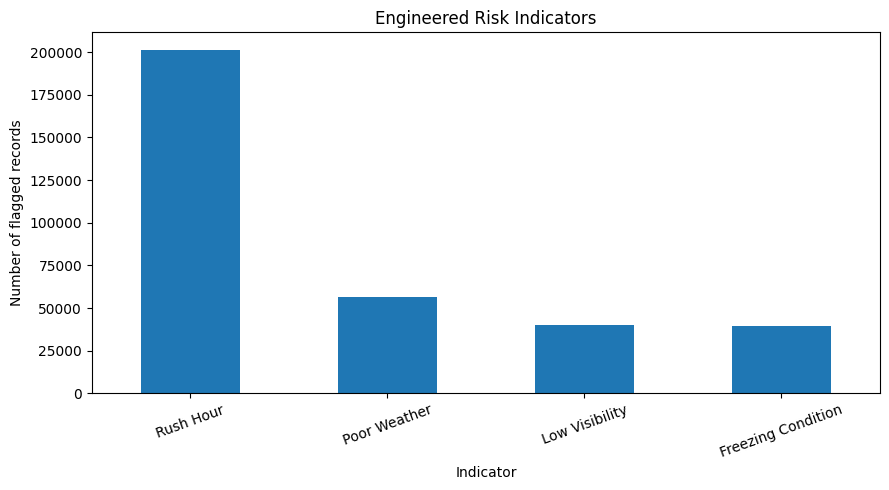

In [ ]:
#STEP 9 — CREATE ENVIRONMENTAL RISK INDICATORS
poor_weather_keywords = [
    "Rain", "Snow", "Fog", "Storm", "Thunder", "Sleet",
    "Hail", "Drizzle", "Ice"
]
weather_pattern = "|".join(poor_weather_keywords)
df["PoorWeather"] = (
    df["Weather_Condition"]
      .fillna("")
      .str.contains(weather_pattern, case=False, regex=True)
      .astype(int)
)

df["LowVisibility"] = (df["Visibility(mi)"] < 5).astype(int)
df["FreezingCondition"] = (df["Temperature(F)"] <= 32).astype(int)
risk_counts = pd.Series({
    "Rush Hour": int(df["RushHour"].sum()),
    "Poor Weather": int(df["PoorWeather"].sum()),
    "Low Visibility": int(df["LowVisibility"].sum()),
    "Freezing Condition": int(df["FreezingCondition"].sum())
})
display(risk_counts.rename("Accidents / records flagged").to_frame())
risk_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Engineered Risk Indicators")
plt.xlabel("Indicator")
plt.ylabel("Number of flagged records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Geographic accident concentration map
import pandas as pd
import plotly.express as px

locations = df[["Start_Lat", "Start_Lng"]].copy()
locations["Start_Lat"] = pd.to_numeric(locations["Start_Lat"], errors="coerce")
locations["Start_Lng"] = pd.to_numeric(locations["Start_Lng"], errors="coerce")
locations = locations.dropna(subset=["Start_Lat", "Start_Lng"])
locations = locations[
    locations["Start_Lat"].between(-90, 90) &
    locations["Start_Lng"].between(-180, 180)
]

locations["Latitude_Cell"] = locations["Start_Lat"].round(2)
locations["Longitude_Cell"] = locations["Start_Lng"].round(2)

hotspot_counts = (
    locations.groupby(["Latitude_Cell", "Longitude_Cell"])
    .size()
    .reset_index(name="Accident_Count")
    .sort_values("Accident_Count", ascending=False)
)

#Displaying the 1,000 cells with the highest accident counts
map_data = hotspot_counts.head(1000).copy()

fig = px.scatter_geo(
    map_data,
    lat="Latitude_Cell",
    lon="Longitude_Cell",
    size="Accident_Count",
    color="Accident_Count",
    hover_data={
        "Latitude_Cell": ":.2f",
        "Longitude_Cell": ":.2f",
        "Accident_Count": True
    },
    size_max=18,
    projection="albers usa",
    scope="usa",
    color_continuous_scale="Plasma",
    title="Geographic Concentration of Recorded Accidents"
)

fig.update_geos(
    showland=True,
    landcolor="rgb(235, 235, 235)",
    showocean=True,
    oceancolor="rgb(220, 235, 245)",
    showcountries=True,
    showsubunits=True,
    showcoastlines=True,
    fitbounds="locations"
)

fig.update_layout(
    height=650,
    margin={"r": 20, "t": 60, "l": 20, "b": 20},
    coloraxis_colorbar_title="Accident count"
)

fig.show()

print("Valid accident coordinates:", len(locations))
print("Geographic cells:", len(hotspot_counts))
print("Larger markers indicate more recorded accidents, not necessarily higher accident risk.")

Valid accident coordinates: 500000
Geographic cells: 124329
Larger markers indicate more recorded accidents, not necessarily higher accident risk.


## 5. Feature selection and engineering

The final modelling table uses 37 features: numerical, categorical and boolean inputs. `Severity` is kept separately as the target.

In [ ]:
#STEP 10 — DEFINE MODEL FEATURES
numerical_features = [
    "Temperature(F)", "Humidity(%)", "Pressure(in)",
    "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
    "Hour", "DayOfWeek", "Month", "Year"
]

categorical_features = [
    "State", "Weather_Condition", "Wind_Direction",
    "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight",
    "Astronomical_Twilight", "TimeOfDay", "Season"
]

boolean_features = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction",
    "No_Exit", "Railway", "Roundabout", "Station", "Stop",
    "Traffic_Calming", "Traffic_Signal", "Turning_Loop",
    "Weekend", "RushHour", "PoorWeather", "LowVisibility",
    "FreezingCondition"
]

#Keeping only features that are present in the dataset.
numerical_features = [c for c in numerical_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]
boolean_features = [c for c in boolean_features if c in df.columns]

features = numerical_features + categorical_features + boolean_features

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Boolean features:", len(boolean_features))
print("Total model input features:", len(features))
print("\nFeature list:")
for feature in features:
    print("-", feature)

assert len(features) == 37, f"Expected 37 model features, found {len(features)}."

Numerical features: 10
Categorical features: 9
Boolean features: 18
Total model input features: 37

Feature list:
- Temperature(F)
- Humidity(%)
- Pressure(in)
- Visibility(mi)
- Wind_Speed(mph)
- Precipitation(in)
- Hour
- DayOfWeek
- Month
- Year
- State
- Weather_Condition
- Wind_Direction
- Sunrise_Sunset
- Civil_Twilight
- Nautical_Twilight
- Astronomical_Twilight
- TimeOfDay
- Season
- Amenity
- Bump
- Crossing
- Give_Way
- Junction
- No_Exit
- Railway
- Roundabout
- Station
- Stop
- Traffic_Calming
- Traffic_Signal
- Turning_Loop
- Weekend
- RushHour
- PoorWeather
- LowVisibility
- FreezingCondition


In [ ]:
#STEP 11 — CREATE X AND y
X=df[features].copy()
y=df["Severity"].copy()

#Convert boolean indicators to integer values once, before the pipeline.
for col in boolean_features:
    # Map string representation 'True'/'False' or actual boolean values to 1/0
    X[col] = X[col].astype(str).str.lower().map({'true': 1, '1': 1, '1.0': 1, 'false': 0, '0': 0, '0.0': 0, 'nan': 0}).fillna(0).astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing target values:", y.isna().sum())

X shape: (500000, 37)
y shape: (500000,)
Missing target values: 0


## 6. Train / validation / test split

A stratified random split is used so each partition retains a similar severity distribution. The split is 70% training, 15% validation and 15% final test. The final test set is not used for selecting the class-weight strategy.

In [ ]:
#STEP 12—TRAIN/VALIDATION/TEST SPLIT
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

validation_ratio = 15 / 85

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=validation_ratio,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Final test records:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

assert len(X_train) + len(X_val) + len(X_test) == len(X)

Training records: 350000
Validation records: 75000
Final test records: 75000
Total: 500000


In [ ]:
#STEP 13—VERIFY CLASS DISTRIBUTION IN EACH SPLIT
def class_distribution(series):
    return (series.value_counts(normalize=True).sort_index() * 100).round(2)

class_distribution_table = pd.DataFrame({
    "Train %": class_distribution(y_train),
    "Validation %": class_distribution(y_val),
    "Test %": class_distribution(y_test)
})

display(class_distribution_table)

,Train %,Validation %,Test %
Severity,,,
1,0.85,0.85,0.85
2,79.63,79.63,79.63
3,16.90,16.90,16.90
4,2.61,2.61,2.61


## 7. Preprocessing pipeline

Numerical values use median imputation. Categorical values use most-frequent imputation followed by one-hot encoding. Boolean indicators use most-frequent imputation. The transformations are inside a scikit-learn pipeline to avoid fitting preprocessing on the final test data.

In [ ]:
#STEP 14 — PREPROCESSING PIPELINE
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

boolean_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
        ("bool", boolean_transformer, boolean_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 8. Baseline model

A majority-class baseline is included so the Random Forest is compared against a simple strategy rather than only against other Random Forest configurations. The baseline predicts the most frequent training class for every case.

In [ ]:
#STEP 15 — MAJORITY-CLASS BASELINE
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

y_val_baseline = baseline_model.predict(X_val)
y_test_baseline = baseline_model.predict(X_test)

baseline_results = pd.DataFrame({
    "Dataset": ["Validation", "Final Test"],
    "Accuracy": [
        accuracy_score(y_val, y_val_baseline),
        accuracy_score(y_test, y_test_baseline)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, y_val_baseline),
        balanced_accuracy_score(y_test, y_test_baseline)
    ],
    "Macro F1": [
        f1_score(y_val, y_val_baseline, average="macro", zero_division=0),
        f1_score(y_test, y_test_baseline, average="macro", zero_division=0)
    ]
})

display(baseline_results.round(4))
print("Baseline class predicted:", baseline_model.classes_[np.argmax(baseline_model.class_prior_)])

,Dataset,Accuracy,Balanced Accuracy,Macro F1
0,Validation,0.7963,0.25,0.2216
1,Final Test,0.7963,0.25,0.2216


Baseline class predicted: 2


## 9. Random Forest class-weight experiment

The dataset is strongly imbalanced, so seven class-weight strategies are tested. Model selection is based on **validation Macro F1**, with Severity 4 recall retained as an important class-level diagnostic.

In [ ]:
#STEP 16 — DEFINE CLASS WEIGHT OPTIONS
weight_options = {
    "No Weight": None,
    "Balanced": "balanced",
    "Balanced Subsample": "balanced_subsample",
    "Custom 1": {1: 2, 2: 1, 3: 2, 4: 4},
    "Custom 2": {1: 2, 2: 1, 3: 2, 4: 6},
    "Custom 3": {1: 2, 2: 1, 3: 2.5, 4: 8},
    "Custom 4": {1: 3, 2: 1, 3: 2.5, 4: 10}
}

for name, weights in weight_options.items():
    print(f"{name}: {weights}")

No Weight: None
Balanced: balanced
Balanced Subsample: balanced_subsample
Custom 1: {1: 2, 2: 1, 3: 2, 4: 4}
Custom 2: {1: 2, 2: 1, 3: 2, 4: 6}
Custom 3: {1: 2, 2: 1, 3: 2.5, 4: 8}
Custom 4: {1: 3, 2: 1, 3: 2.5, 4: 10}


In [ ]:
#STEP 17 — TRAIN AND VALIDATE ALL WEIGHT STRATEGIES
validation_results=[]
trained_models={}

RF_N_ESTIMATORS=50
RF_MAX_DEPTH=12
RF_MIN_SAMPLES_LEAF=2
RF_MAX_FEATURES="sqrt"

for name, weights in weight_options.items():
    print("\n====================================")
    print("Training:", name)
    print("====================================")

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=RF_N_ESTIMATORS,
            max_depth=RF_MAX_DEPTH,
            min_samples_leaf=RF_MIN_SAMPLES_LEAF,
            max_features=RF_MAX_FEATURES,
            class_weight=weights,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)
    y_val_pred=model.predict(X_val)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred),
        "Macro Precision": precision_score(y_val, y_val_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_val, y_val_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_val, y_val_pred, average="macro", zero_division=0),
        "Severity 4 Recall": recall_score(y_val, y_val_pred, labels=[4], average="macro", zero_division=0)
    })
    trained_models[name]=model

validation_df=pd.DataFrame(validation_results)
validation_df=validation_df.sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(validation_df.round(4))


Training: No Weight

Training: Balanced

Training: Balanced Subsample

Training: Custom 1

Training: Custom 2

Training: Custom 3

Training: Custom 4


,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Severity 4 Recall
0,Custom 4,0.7821,0.3375,0.6328,0.3375,0.3465,0.0500
1,Custom 3,0.7813,0.3360,0.4242,0.3360,0.3357,0.0194
2,Balanced Subsample,0.5191,0.5834,0.3499,0.5834,0.3262,0.2679
3,Balanced,0.5159,0.5828,0.3501,0.5828,0.3251,0.2730
4,Custom 2,0.7994,0.2919,0.4594,0.2919,0.2961,0.0071
5,Custom 1,0.7995,0.2900,0.5796,0.2900,0.2924,0.0005
6,No Weight,0.7967,0.2508,0.3672,0.2508,0.2234,0.0000


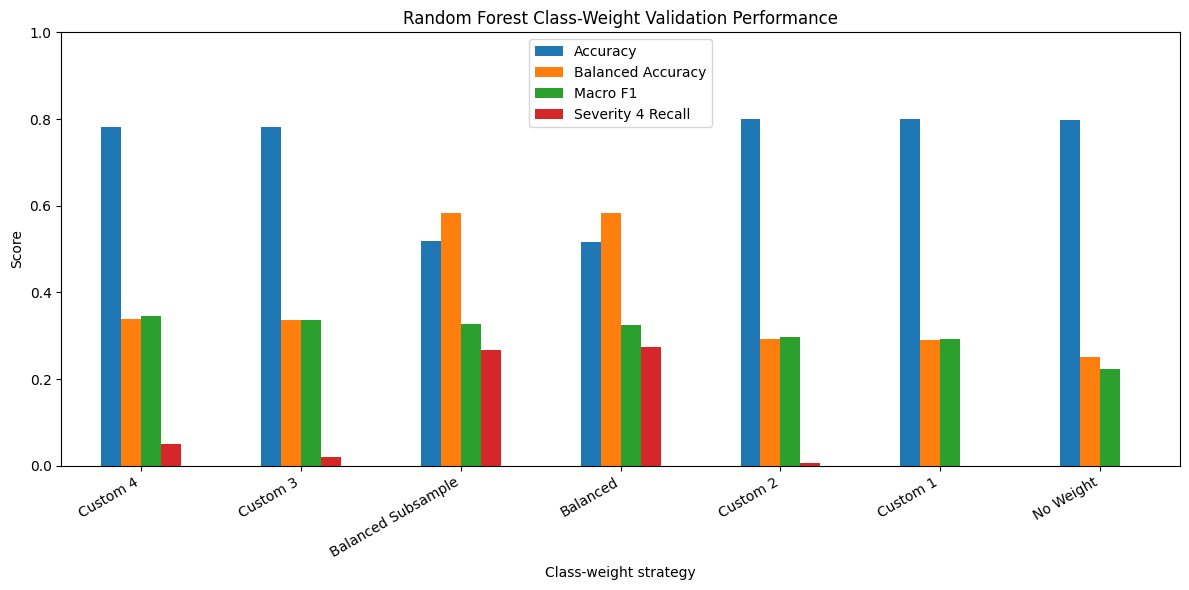

In [ ]:
#STEP 18 — VALIDATION PERFORMANCE PLOT

plot_df=validation_df.set_index("Model")
plot_df[["Accuracy", "Balanced Accuracy", "Macro F1", "Severity 4 Recall"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Random Forest Class-Weight Validation Performance")
plt.ylabel("Score")
plt.xlabel("Class-weight strategy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#STEP 19 — SELECT BEST STRATEGY USING VALIDATION MACRO F1
best_model_name = validation_df.iloc[0]["Model"]
best_validation_row = validation_df.iloc[0]
best_class_weight = weight_options[best_model_name]

print("Selected class-weight strategy:",best_model_name)
print("Validation Accuracy:",round(best_validation_row["Accuracy"], 4))
print("Validation Balanced Accuracy:",round(best_validation_row["Balanced Accuracy"], 4))
print("Validation Macro F1:",round(best_validation_row["Macro F1"], 4))
print("Validation Severity 4 Recall:",round(best_validation_row["Severity 4 Recall"], 4))

Selected class-weight strategy: Custom 4
Validation Accuracy: 0.7821
Validation Balanced Accuracy: 0.3375
Validation Macro F1: 0.3465
Validation Severity 4 Recall: 0.05


## 10. Final model training and untouched test evaluation

After selecting the class-weight strategy using the validation set, the training and validation observations are combined. The final model is then evaluated once on the held-out test set.

In [ ]:
#STEP 20 — COMBINE TRAINING AND VALIDATION DATA

X_final_train = pd.concat([X_train, X_val], axis=0)
y_final_train = pd.concat([y_train, y_val], axis=0)

print("Final training records:", len(X_final_train))
print("Final training shape:", X_final_train.shape)

Final training records: 425000
Final training shape: (425000, 37)


In [ ]:
#STEP 21 — BUILD AND TRAIN FINAL MODEL
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        max_features=RF_MAX_FEATURES,
        class_weight=best_class_weight,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training final model...")
final_model.fit(X_final_train, y_final_train)
print("Final model training completed.")

Training final model...
Final model training completed.


In [ ]:
#STEP 22—FINAL TEST PREDICTIONS

y_test_pred = final_model.predict(X_test)
print("Final test predictions completed.")
print("Number of predictions:", len(y_test_pred))

Final test predictions completed.
Number of predictions: 75000


MULTICLASS PROBABILITY DIAGNOSTIC
Multiclass Brier score: 0.3685
Lower Brier scores indicate better probabilistic predictions.
Interpret the score alongside class imbalance and other metrics.


,Mean_Confidence,Observed_Accuracy,Number_of_Predictions
Bin,,,
"(0.3, 0.4]",0.382,0.426,1195
"(0.4, 0.5]",0.449,0.530,20091
"(0.5, 0.6]",0.554,0.797,21719
"(0.6, 0.7]",0.647,0.924,20928
"(0.7, 0.8]",0.737,0.969,9431
"(0.8, 0.9]",0.824,0.994,1636


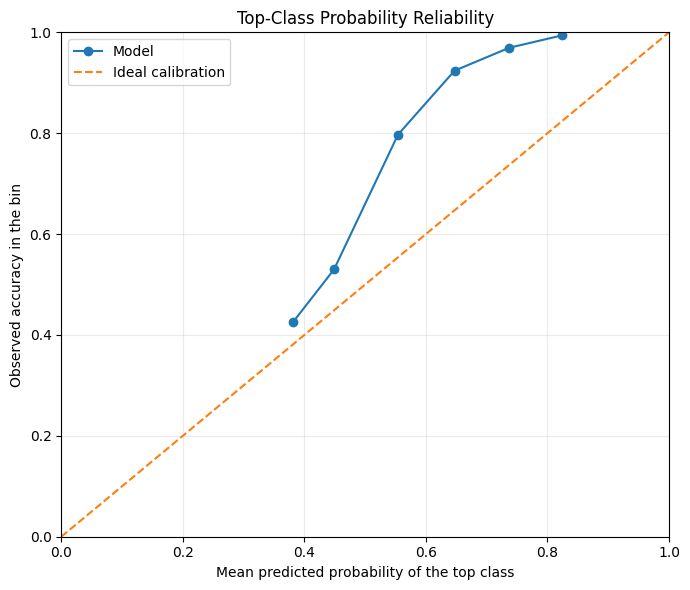

Note: This diagram evaluates the probability of the top predicted class. It does not establish that every individual class probability is calibrated.


In [ ]:
#Continuing the final test predictions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the untouched final test set.
calibration_probabilities = final_model.predict_proba(X_test)
calibration_classes = final_model.named_steps["classifier"].classes_

calibration_predictions = calibration_classes[
    np.argmax(calibration_probabilities, axis=1)
]

# Multiclass Brier score: lower is better, with 0 being ideal.
actual_one_hot = np.column_stack([
    (np.asarray(y_test) == class_label).astype(int)
    for class_label in calibration_classes
])

multiclass_brier = np.mean(
    np.sum(
        (calibration_probabilities - actual_one_hot) ** 2,
        axis=1
    )
)

print("MULTICLASS PROBABILITY DIAGNOSTIC")
print(f"Multiclass Brier score: {multiclass_brier:.4f}")
print("Lower Brier scores indicate better probabilistic predictions.")
print("Interpret the score alongside class imbalance and other metrics.")

# Top-label reliability: compare the model's highest probability
# with the proportion of correct predictions in each confidence bin.
top_confidence = calibration_probabilities.max(axis=1)
top_correct = (
    np.asarray(calibration_predictions) == np.asarray(y_test)
).astype(int)

calibration_table = pd.DataFrame({
    "Confidence": top_confidence,
    "Correct": top_correct
})

calibration_table["Bin"] = pd.cut(
    calibration_table["Confidence"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

reliability = (
    calibration_table.groupby("Bin", observed=False)
    .agg(
        Mean_Confidence=("Confidence", "mean"),
        Observed_Accuracy=("Correct", "mean"),
        Number_of_Predictions=("Correct", "size")
    )
    .dropna(subset=["Mean_Confidence", "Observed_Accuracy"])
)

display(reliability.round(3))

# Reliability diagram
plt.figure(figsize=(7, 6))
plt.plot(
    reliability["Mean_Confidence"],
    reliability["Observed_Accuracy"],
    marker="o",
    label="Model"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Ideal calibration")
plt.xlabel("Mean predicted probability of the top class")
plt.ylabel("Observed accuracy in the bin")
plt.title("Top-Class Probability Reliability")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Note: This diagram evaluates the probability of the top predicted "
    "class. It does not establish that every individual class probability "
    "is calibrated."
)


In [ ]:
#STEP 23 — FINAL TEST METRICS

final_accuracy = accuracy_score(y_test, y_test_pred)
final_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
final_recall = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
final_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy", "Balanced Accuracy", "Macro Precision",
        "Macro Recall", "Macro F1"
    ],
    "Score": [
        final_accuracy, final_balanced_accuracy, final_precision,
        final_recall, final_f1
    ]
})

display(final_metrics.round(4))

,Metric,Score
0,Accuracy,0.7810
1,Balanced Accuracy,0.3427
2,Macro Precision,0.6315
3,Macro Recall,0.3427
4,Macro F1,0.3458


In [ ]:
#STEP 24 — CLASSIFICATION REPORT AND CLASS-LEVEL RECALL
print(classification_report(
    y_test, y_test_pred,
    labels=[1, 2, 3, 4],
    digits=4,
    zero_division=0
))

class_recall = pd.Series(
    recall_score(y_test, y_test_pred, labels=[1, 2, 3, 4], average=None, zero_division=0),
    index=["Severity 1", "Severity 2", "Severity 3", "Severity 4"],
    name="Recall"
)

display((class_recall * 100).round(2).to_frame())
severity4_recall = recall_score(y_test, y_test_pred, labels=[4], average="macro", zero_division=0)
print("Severity 4 Recall:", round(severity4_recall, 4))

              precision    recall  f1-score   support

           1     1.0000    0.0031    0.0062       641
           2     0.8548    0.8852    0.8697     59721
           3     0.4389    0.4443    0.4416     12678
           4     0.2322    0.0383    0.0657      1960

    accuracy                         0.7810     75000
   macro avg     0.6315    0.3427    0.3458     75000
weighted avg     0.7695    0.7810    0.7690     75000



,Recall
Severity 1,0.31
Severity 2,88.52
Severity 3,44.43
Severity 4,3.83


Severity 4 Recall: 0.0383


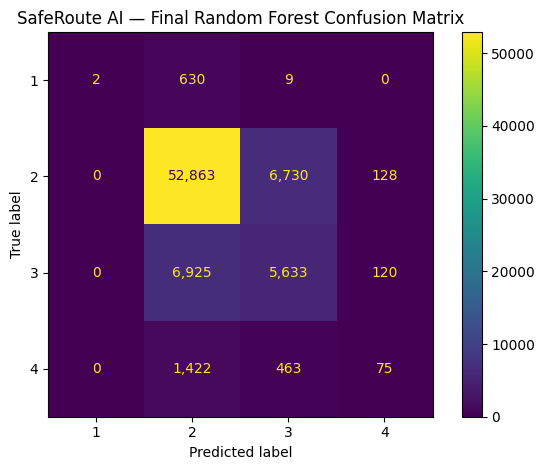

In [ ]:
#STEP 25 — FINAL CONFUSION MATRIX
cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1, 2, 3, 4]
)
disp.plot(values_format=",")
plt.title("SafeRoute AI — Final Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Error analysis

The confusion matrix and class-level recall are used to identify where the model performs poorly. In particular, the rare Severity 4 class should not be hidden by overall accuracy.

In [ ]:
#STEP 26 — ERROR ANALYSIS TABLE
error_analysis=pd.DataFrame({
    "Actual Severity": y_test.values,
    "Predicted Severity": y_test_pred
})

error_analysis["Correct"]=(
    error_analysis["Actual Severity"]==error_analysis["Predicted Severity"]
)

error_summary = (
    error_analysis
    .groupby("Actual Severity")
    .agg(
        Cases=("Actual Severity", "size"),
        Correct=("Correct", "sum")
    )
)
error_summary["Recall"] = (error_summary["Correct"] / error_summary["Cases"]).round(4)
error_summary["Error Rate"] = (1 - error_summary["Recall"]).round(4)

display(error_summary)

print("Total test errors:", int((~error_analysis["Correct"]).sum()))
print("Total test cases:", len(error_analysis))

,Cases,Correct,Recall,Error Rate
Actual Severity,,,,
1,641,2,0.0031,0.9969
2,59721,52863,0.8852,0.1148
3,12678,5633,0.4443,0.5557
4,1960,75,0.0383,0.9617


Total test errors: 16427
Total test cases: 75000


## 12. Sample scenario prediction and uncertainty

The trained Random Forest can produce a severity class and class probabilities for an individual accident record. This is the coding evidence for the proposed scenario-based AI panel. The example below uses one held-out test record; it does **not** represent a live road-safety alert.

In [ ]:
#STEP 27— SAMPLE AI PREDICTION + PROBABILITIES
#Selecting one held-out test observation as a reproducible demonstration.
sample_case = X_test.iloc[[0]].copy()
sample_actual = int(y_test.iloc[0])

sample_prediction = int(final_model.predict(sample_case)[0])
sample_probabilities = final_model.predict_proba(sample_case)[0]

#Pipeline classes are the same labels used by the Random Forest.
model_classes = final_model.named_steps["classifier"].classes_

probability_table = pd.DataFrame({
    "Severity": model_classes,
    "Probability": sample_probabilities
})
probability_table["Probability %"] = (probability_table["Probability"] * 100).round(2)

print("Sample test case actual Severity:", sample_actual)
print("Predicted Severity:", sample_prediction)
print("\nPrediction probabilities:")
display(probability_table)

Sample test case actual Severity: 2
Predicted Severity: 2

Prediction probabilities:


,Severity,Probability,Probability %
0,1,0.012903,1.29
1,2,0.673579,67.36
2,3,0.146953,14.70
3,4,0.166565,16.66


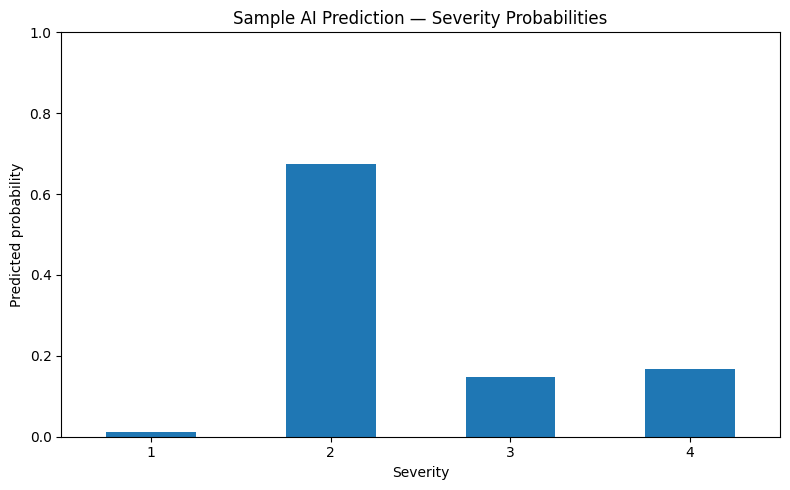

In [ ]:
#STEP 28 — VISUALISE SAMPLE PREDICTION PROBABILITIES
probability_table.set_index("Severity")["Probability"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Sample AI Prediction — Severity Probabilities")
plt.xlabel("Severity")
plt.ylabel("Predicted probability")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 13. Interactive What-if Scenario Prediction

This interface allows users to change accident-related conditions and
investigate how the trained Random Forest model's predicted severity
and class probabilities respond.

The scenario starts with representative values from a held-out record.
Derived features are updated when their underlying inputs change.
Predictions are model estimates and should not be treated as guaranteed
real-world outcomes.


In [ ]:
#INTERACTIVE WHAT-IF SCENARIO PREDICTION
#Uses the existing trained final_model and feature definitions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

#Derived features that must be recalculated from their inputs
derived_features = {
    "TimeOfDay", "Season", "Weekend", "RushHour",
    "PoorWeather", "LowVisibility", "FreezingCondition"
}

#Start with one held-out test record.
#Missing values are replaced with training-set representative values.
scenario_base = X_test.iloc[0].copy()

for col in numerical_features:
    if col in X_train.columns and pd.isna(scenario_base[col]):
        scenario_base[col] = X_train[col].median()

for col in categorical_features:
    if col in X_train.columns and pd.isna(scenario_base[col]):
        modes = X_train[col].mode(dropna=True)
        if len(modes):
            scenario_base[col] = modes.iloc[0]

for col in boolean_features:
    if col in X_train.columns and pd.isna(scenario_base[col]):
        modes = X_train[col].mode(dropna=True)
        scenario_base[col] = modes.iloc[0] if len(modes) else 0

#Creating controls for the model's input features
scenario_widgets = {}

integer_features = {"Hour", "DayOfWeek", "Month", "Year"}
for col in features:
    if col in derived_features:
        continue
    value = scenario_base[col]
    if col in numerical_features:
        value = float(value)
        if col in integer_features:
            control = widgets.BoundedIntText(
                value=int(round(value)),
                min=0,
                max=2100 if col == "Year" else
                    23 if col == "Hour" else
                    6 if col == "DayOfWeek" else
                    12,
                description=col,
                style={"description_width": "initial"},
                layout=widgets.Layout(width="320px")
            )
        else:
            control = widgets.FloatText(
                value=value,
                description=col,
                style={"description_width": "initial"},
                layout=widgets.Layout(width="320px")
            )
    elif col in categorical_features:
        options = sorted(
            X_train[col].dropna().astype(str).unique().tolist()
        )
        current_value = str(value)
        if current_value not in options:
            options.append(current_value)
            options = sorted(options)
        control = widgets.Dropdown(
            options=options,
            value=current_value,
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="420px")
        )
    elif col in boolean_features:
        control = widgets.Checkbox(
            value=bool(value),
            description=col,
            indent=False,
            layout=widgets.Layout(width="250px")
        )
    else:
        continue
    scenario_widgets[col] = control
#Grouping controls to make the interface easier to use
numeric_controls = [
    control for col, control in scenario_widgets.items()
    if col in numerical_features
]
categorical_controls = [
    control for col, control in scenario_widgets.items()
    if col in categorical_features
]
road_controls = [
    control for col, control in scenario_widgets.items()
    if col in boolean_features
]
input_sections = widgets.Accordion(
    children=[
        widgets.VBox(numeric_controls),
        widgets.VBox(categorical_controls),
        widgets.VBox(road_controls)
    ],
    selected_index=None
)
input_sections.set_title(0,"Weather and time inputs")
input_sections.set_title(1,"Location and environmental categories")
input_sections.set_title(2,"Road and infrastructure indicators")

#Recalculating derived features consistently
def apply_derived_features(row):
    """Updating engineered indicators from the scenario inputs."""
    hour = int(row["Hour"])
    day_of_week = int(row["DayOfWeek"])
    month = int(row["Month"])
    temperature = float(row["Temperature(F)"])
    visibility = float(row["Visibility(mi)"])
    weather = str(row["Weather_Condition"])
    # Match the notebook's time-of-day definitions.
    if 5 <= hour < 12:
        row["TimeOfDay"] = "Morning"
    elif 12 <= hour < 17:
        row["TimeOfDay"] = "Afternoon"
    elif 17 <= hour < 21:
        row["TimeOfDay"] = "Evening"
    else:
        row["TimeOfDay"] = "Night"
    #Seasonal feature for the Northern Hemisphere dataset.
    if month in [12, 1, 2]:
        row["Season"] = "Winter"
    elif month in [3, 4, 5]:
        row["Season"] = "Spring"
    elif month in [6, 7, 8]:
        row["Season"] = "Summer"
    else:
        row["Season"] = "Autumn"
    #pandas day-of-week convention: Monday=0, Sunday=6.
    row["Weekend"] = int(day_of_week >= 5)
    #Rush hour: 07:00–09:59 and 16:00–18:59.
    row["RushHour"] = int(
        (7 <= hour < 10) or (16 <= hour < 19)
    )
    #Weather indicator based on the notebook's keyword approach.
    poor_weather_pattern = (
        r"Rain|Snow|Fog|Storm|Thunder|Sleet|Hail|Drizzle|Ice"
    )
    row["PoorWeather"] = int(
        pd.Series([weather]).str.contains(
            poor_weather_pattern,
            case=False,
            regex=True
        ).iloc[0]
    )
    row["LowVisibility"] = int(visibility < 5)
    row["FreezingCondition"] = int(temperature <= 32)
    return row
#Predicting and showing the class probabilities
prediction_output = widgets.Output()
def run_what_if_prediction(_):
    with prediction_output:
        clear_output(wait=True)
        #Original representative case.
        row = scenario_base.copy()
        #Apply values chosen by the user.
        for col, control in scenario_widgets.items():
            row[col] = control.value
        #Ensure derived features match the changed inputs.
        row = apply_derived_features(row)
        #Match the original model feature order exactly.
        scenario_input = pd.DataFrame(
            [row[features].to_dict()],
            columns=features
        )
        #Convert checkbox indicators to integer values.
        for col in boolean_features:
            scenario_input[col] = scenario_input[col].astype(int)
        #Use the trained pipeline: preprocessing + classifier.
        predicted_class = final_model.predict(scenario_input)[0]
        probabilities = final_model.predict_proba(scenario_input)[0]
        classes = final_model.named_steps["classifier"].classes_
        results = pd.DataFrame({
            "Severity class": classes,
            "Estimated probability (%)": np.round(
                probabilities * 100, 2
            )
        })
        print("WHAT-IF SCENARIO RESULT")
        print("Predicted severity:", int(predicted_class))
        print(
            "Highest estimated class probability:",
            f"{probabilities.max() * 100:.2f}%"
        )
        sorted_probs = np.sort(probabilities)
        probability_gap = (
            sorted_probs[-1] - sorted_probs[-2]
            if len(sorted_probs) > 1 else sorted_probs[-1]
        )
        print(
            "Gap between the two highest probabilities:",
            f"{probability_gap * 100:.2f} percentage points"
        )
        display(results)
        #Plot probabilities with labels.
        fig, ax = plt.subplots(figsize=(8, 4.5))
        bars = ax.bar(
            [str(c) for c in classes],
            probabilities * 100
        )
        ax.bar_label(
            bars,
            labels=[f"{p * 100:.1f}%" for p in probabilities],
            padding=3
        )
        ax.set_title("Estimated Probability by Severity Class")
        ax.set_xlabel("Severity class")
        ax.set_ylabel("Estimated probability (%)")
        ax.set_ylim(0, min(110, max(30, probabilities.max() * 120)))
        ax.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()
        print(
            "Interpretation:the predicted class is the model's most likely class for the entered scenario."
            "The probabilities are model estimates, not guaranteed real-world outcomes. "
        )
predict_button = widgets.Button(
    description="Predict Scenario",
    button_style="primary",
    icon="check"
)
predict_button.on_click(run_what_if_prediction)
display(
    widgets.VBox([
        widgets.HTML(
            "<h3>SafeRoute AI — What-if Scenario</h3>"
            "<p>Change the inputs, then select Predict Scenario. "
            "Unchanged inputs retain the initial example values.</p>"
        ),
        input_sections,
        predict_button,
        prediction_output
    ])
)


## 13. Model feature importance

Random Forest feature importance is included as a simple model-interpretation aid. Because categorical variables are one-hot encoded, the chart refers to transformed model features rather than treating the original categorical field as one single numeric variable.

,Feature,Importance
9,num__Year,0.227066
217,bool__Traffic_Signal,0.052595
13,cat__State_CA,0.052049
208,bool__Crossing,0.043772
2,num__Pressure(in),0.038429
70,cat__Weather_Condition_Fair,0.038202
205,cat__Season_Winter,0.034155
6,num__Hour,0.029546
8,num__Month,0.028767
4,num__Wind_Speed(mph),0.023617


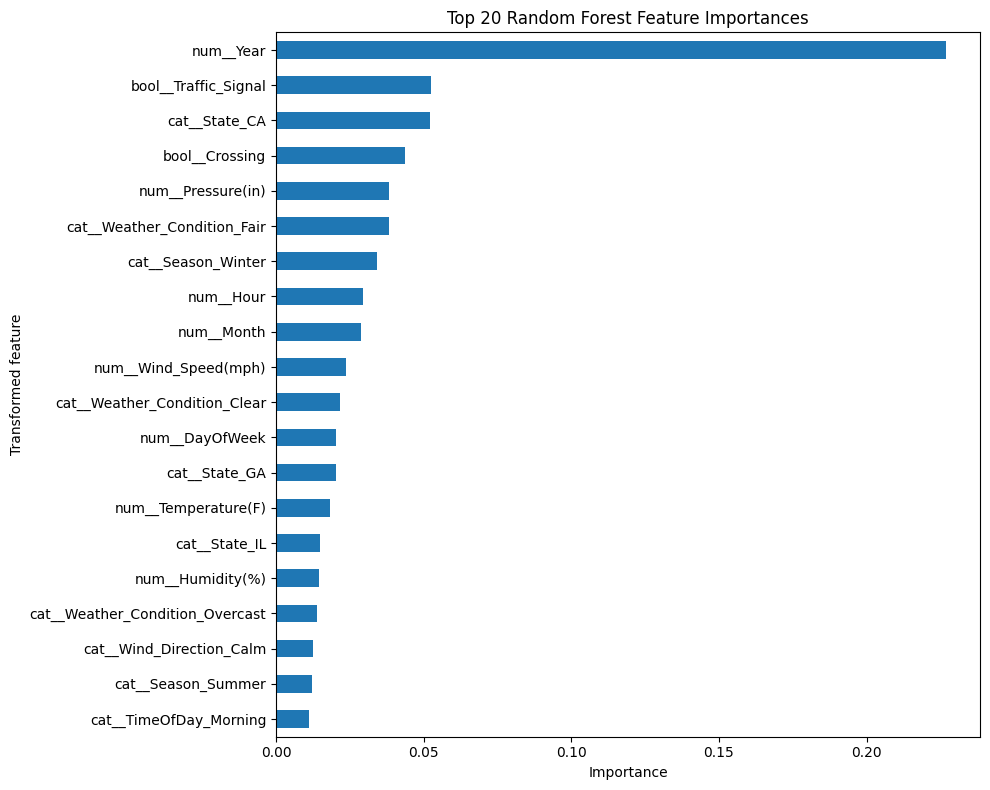

In [ ]:
#STEP 29 — FEATURE IMPORTANCE
classifier = final_model.named_steps["classifier"]
preprocessor_fitted = final_model.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()
importances = classifier.feature_importances_

importance_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
      .sort_values("Importance", ascending=False)
      .head(20)
      .sort_values("Importance", ascending=True)
)

display(importance_df.sort_values("Importance", ascending=False).head(20))

importance_df.set_index("Feature")["Importance"].plot(
    kind="barh", figsize=(10, 8)
)
plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Transformed feature")
plt.tight_layout()
plt.show()

## 15. Compare Experiment 1, 2 and 3

The following comparison preserves the previously reported experiment results. It is used for project-level context only; the Experiment 3 class-weight selection itself is based on its validation results above.

,Experiment,Accuracy,Balanced Accuracy,Macro F1
0,Experiment 1 RF,0.6072,0.4958,0.3351
1,Experiment 2 Improved RF,0.7588,0.4237,0.4110
2,Experiment 3 Tuned RF,0.7810,0.3427,0.3458


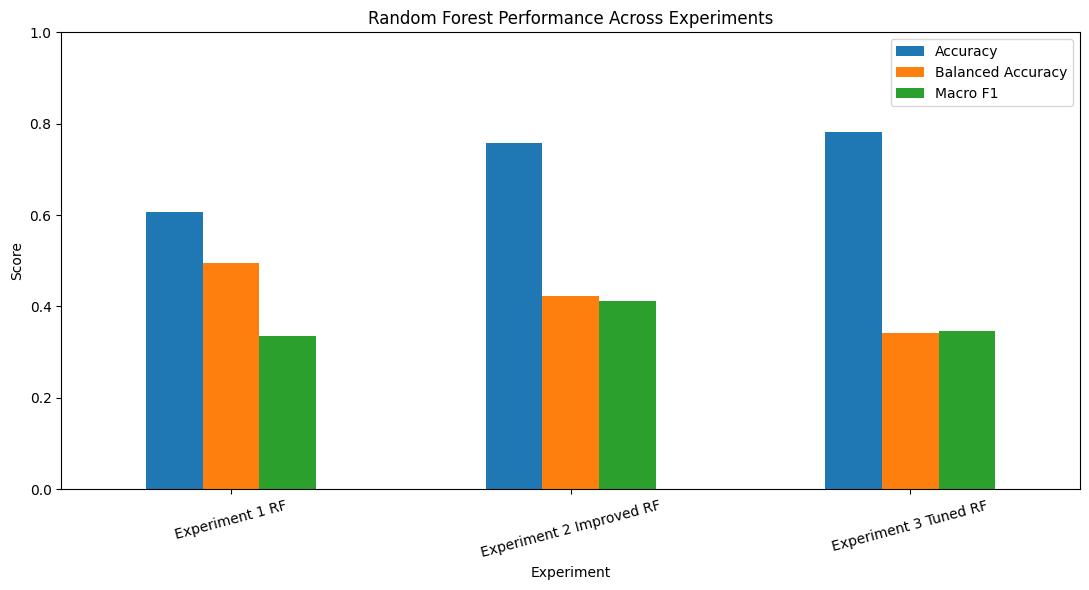

In [ ]:
#STEP 30 — EXPERIMENT COMPARISON
experiment_comparison = pd.DataFrame({
    "Experiment": [
        "Experiment 1 RF",
        "Experiment 2 Improved RF",
        "Experiment 3 Tuned RF"
    ],
    "Accuracy": [0.6072, 0.7588, final_accuracy],
    "Balanced Accuracy": [0.4958, 0.4237, final_balanced_accuracy],
    "Macro F1": [0.3351, 0.4110, final_f1]
})

display(experiment_comparison.round(4))

experiment_comparison.set_index("Experiment")[[
    "Accuracy", "Balanced Accuracy", "Macro F1"
]].plot(kind="bar", figsize=(11, 6))
plt.title("Random Forest Performance Across Experiments")
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 16. Final reproducibility summary

This notebook demonstrates the complete preliminary ML workflow required for the SafeRoute AI prototype: data loading → data checks → EDA → feature engineering → preprocessing → baseline → class-weight experiments → validation-based selection → final model → test evaluation → error analysis → scenario prediction → probability output → feature importance.

### Important interpretation

The model is a **decision-support prototype**, not an autonomous safety decision system. Overall accuracy must be interpreted alongside balanced accuracy, Macro F1 and class-level recall because the severity classes are highly imbalanced. In particular, poor recall for a rare class would limit the model's suitability for high-stakes automated decisions.

### Reproducibility settings

- Random seed: `42`
- Train/validation/test split: `70% / 15% / 15%`
- Stratification: enabled
- Random Forest trees: `50`
- Maximum depth: `12`
- Minimum samples per leaf: `2`
- Maximum features: `sqrt`
- Final class-weight strategy: selected using validation Macro F1
- Final test set: held out from model selection

## 17. Interactive SafeRoute AI dashboard

This section provides the interactive dashboard developed for SafeRoute AI. It uses Plotly and ipywidgets to allow users to explore the historical accident data through Severity, Time of Day, Season, Rush Hour and Weekend filters. The dashboard displays filtered accident KPIs, historical distributions, risk factors and the final model's evaluation metrics.

The dashboard is an exploratory and decision-support interface. Historical observations are kept separate from model evaluation results; the final model was trained before the dashboard filters are applied.


In [ ]:
#STEP 31 — INTERACTIVE SAFEROUTE AI DASHBOARD

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

#Google Colab widget support
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except Exception:
    pass
#FILTER OPTIONS
severity_options = ["All"] + sorted(
    df["Severity"].dropna().unique().tolist()
)
time_options = ["All"] + [
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]
season_options = ["All"] + [
    x for x in ["Winter", "Spring", "Summer", "Autumn"]
    if "Season" in df.columns and x in df["Season"].dropna().unique()
]
rush_options = ["All", "Yes", "No"]
weekend_options = ["All", "Yes", "No"]

#FILTER WIDGETS
severity_filter = widgets.Dropdown(
    options=severity_options,
    value="All",
    description="Severity:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="230px")
)
time_filter = widgets.Dropdown(
    options=time_options,
    value="All",
    description="Time of Day:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="280px")
)
season_filter = widgets.Dropdown(
    options=season_options,
    value="All",
    description="Season:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="230px")
)
rush_filter = widgets.Dropdown(
    options=rush_options,
    value="All",
    description="Rush Hour:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="230px")
)
weekend_filter = widgets.Dropdown(
    options=weekend_options,
    value="All",
    description="Weekend:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="230px")
)
reset_button = widgets.Button(
    description="Reset Filters",
    icon="refresh",
    layout=widgets.Layout(width="140px")
)
dashboard_output = widgets.Output()

#DASHBOARD UPDATE FUNCTION
def update_dashboard(*args):

    with dashboard_output:
        clear_output(wait=True)
        filtered_df = df.copy()
        #Severity
        if severity_filter.value != "All":
            filtered_df = filtered_df[
                filtered_df["Severity"] == severity_filter.value
            ]
        #Time of day
        if time_filter.value != "All":
            filtered_df = filtered_df[
                filtered_df["TimeOfDay"] == time_filter.value
            ]
        #Season
        if season_filter.value != "All" and "Season" in filtered_df.columns:
            filtered_df = filtered_df[
                filtered_df["Season"] == season_filter.value
            ]
        #Rush hour
        if rush_filter.value != "All":
            rush_value = 1 if rush_filter.value == "Yes" else 0
            filtered_df = filtered_df[
                filtered_df["RushHour"] == rush_value
            ]
        #Weekend
        if weekend_filter.value != "All":
            weekend_value = 1 if weekend_filter.value == "Yes" else 0
            filtered_df = filtered_df[
                filtered_df["Weekend"] == weekend_value
            ]
        #No matching records
        if len(filtered_df) == 0:
            print("No accidents match the selected filters.")
            return
        #FILTERED DATA SUMMARIES
        severity_counts = (
            filtered_df["Severity"]
            .value_counts()
            .reindex([1, 2, 3, 4], fill_value=0)
        )
        time_order = [
            "Morning",
            "Afternoon",
            "Evening",
            "Night"
        ]
        time_counts = (
            filtered_df["TimeOfDay"]
            .value_counts()
            .reindex(time_order, fill_value=0)
        )
        risk_factors = pd.DataFrame({
            "Risk Factor": [
                "Rush Hour",
                "Poor Weather",
                "Low Visibility",
                "Freezing Condition"
            ],
            "Accidents": [
                filtered_df["RushHour"].sum(),
                filtered_df["PoorWeather"].sum(),
                filtered_df["LowVisibility"].sum(),
                filtered_df["FreezingCondition"].sum()
            ]
        })
        risk_factors["Percentage"] = (
            risk_factors["Accidents"] / len(filtered_df) * 100
        )
        total_accidents = len(filtered_df)
        severity_4_count = (
            filtered_df["Severity"] == 4
        ).sum()
        average_severity = filtered_df["Severity"].mean()
        #FINAL MODEL METRICS
        model_metrics = pd.DataFrame({
            "Metric": [
                "Accuracy",
                "Balanced Accuracy",
                "Macro Precision",
                "Macro Recall",
                "Macro F1",
                "Severity 4 Recall"
            ],
            "Score": [
                final_accuracy,
                final_balanced_accuracy,
                final_precision,
                final_recall,
                final_f1,
                severity4_recall
            ]
        })
        #CREATE DASHBOARD
        fig = make_subplots(
            rows=5,
            cols=2,
            specs=[
                [{"type": "indicator"}, {"type": "indicator"}],
                [{"type": "indicator"}, {"type": "indicator"}],
                [{"type": "xy"}, {"type": "xy"}],
                [{"type": "xy"}, {"type": "xy"}],
                [{"type": "heatmap", "colspan": 2}, None]
            ],
            subplot_titles=[
                "Total Accidents",
                "Average Severity",
                "Severity 4 Cases",
                "Final Model Accuracy",
                "Accidents by Severity",
                "Accidents by Time of Day",
                "Risk Factors",
                "Final Model Performance",
                "Final Confusion Matrix"
            ],
            vertical_spacing=0.08,
            horizontal_spacing=0.10
        )
        #KPI 1
        fig.add_trace(
            go.Indicator(
                mode="number",
                value=total_accidents,
                number={"valueformat": ","}
            ),
            row=1, col=1
        )

        #KPI 2
        fig.add_trace(
            go.Indicator(
                mode="number",
                value=average_severity,
                number={"valueformat": ".2f"}
            ),
            row=1, col=2
        )
        #KPI 3
        fig.add_trace(
            go.Indicator(
                mode="number",
                value=severity_4_count,
                number={"valueformat": ","}
            ),
            row=2, col=1
        )
        #KPI 4
        fig.add_trace(
            go.Indicator(
                mode="number",
                value=final_accuracy * 100,
                number={
                    "suffix": "%",
                    "valueformat": ".2f"
                }
            ),
            row=2, col=2
        )
        #Severity distribution
        fig.add_trace(
            go.Bar(
                x=[
                    "Severity 1",
                    "Severity 2",
                    "Severity 3",
                    "Severity 4"
                ],
                y=severity_counts.values,
                text=[f"{x:,}" for x in severity_counts.values],
                textposition="auto",
                hovertemplate=(
                    "<b>%{x}</b><br>"
                    "Accidents: %{y:,}"
                    "<extra></extra>"
                )
            ),
            row=3, col=1
        )
        #Time of day
        fig.add_trace(
            go.Bar(
                x=time_counts.index,
                y=time_counts.values,
                text=[f"{x:,}" for x in time_counts.values],
                textposition="auto",
                hovertemplate=(
                    "<b>%{x}</b><br>"
                    "Accidents: %{y:,}"
                    "<extra></extra>"
                )
            ),
            row=3, col=2
        )
        #Risk factors
        fig.add_trace(
            go.Bar(
                x=risk_factors["Risk Factor"],
                y=risk_factors["Percentage"],
                customdata=risk_factors["Accidents"],
                text=[
                    f"{x:.1f}%"
                    for x in risk_factors["Percentage"]
                ],
                textposition="auto",
                hovertemplate=(
                    "<b>%{x}</b><br>"
                    "Accidents: %{customdata:,}<br>"
                    "Percentage: %{y:.2f}%"
                    "<extra></extra>"
                )
            ),
            row=4, col=1
        )
        #Final model performance
        fig.add_trace(
            go.Bar(
                x=model_metrics["Metric"],
                y=model_metrics["Score"],
                text=[
                    f"{x:.3f}"
                    for x in model_metrics["Score"]
                ],
                textposition="auto",
                hovertemplate=(
                    "<b>%{x}</b><br>"
                    "Score: %{y:.4f}"
                    "<extra></extra>"
                )
            ),
            row=4, col=2
        )
        #Confusion matrix
        fig.add_trace(
            go.Heatmap(
                z=cm,
                x=[
                    "Severity 1",
                    "Severity 2",
                    "Severity 3",
                    "Severity 4"
                ],
                y=[
                    "Severity 1",
                    "Severity 2",
                    "Severity 3",
                    "Severity 4"
                ],
                text=cm,
                texttemplate="%{text:,}",
                hovertemplate=(
                    "Actual: %{y}<br>"
                    "Predicted: %{x}<br>"
                    "Count: %{z:,}"
                    "<extra></extra>"
                )
            ),
            row=5, col=1
        )
        #Axis labels
        fig.update_xaxes(
            title_text="Severity",
            row=3, col=1
        )
        fig.update_yaxes(
            title_text="Number of Accidents",
            row=3, col=1
        )
        fig.update_xaxes(
            title_text="Time of Day",
            row=3, col=2
        )
        fig.update_yaxes(
            title_text="Number of Accidents",
            row=3, col=2
        )
        fig.update_xaxes(
            title_text="Risk Factor",
            row=4, col=1
        )
        fig.update_yaxes(
            title_text="Accidents (%)",
            row=4, col=1
        )
        fig.update_xaxes(
            title_text="Metric",
            row=4, col=2
        )
        fig.update_yaxes(
            title_text="Score",
            range=[0, 1],
            row=4, col=2
        )
        fig.update_layout(
            title={
                "text": (
                    "SafeRoute AI — Road Accident Analytics Dashboard"
                    "<br><sup>"
                    "Interactive historical analysis and final model performance"
                    "</sup>"
                ),
                "x": 0.5,
                "xanchor": "center"
            },
            height=1600,
            width=1400,
            template="plotly_white",
            showlegend=False,
            margin={
                "l": 60,
                "r": 60,
                "t": 110,
                "b": 60
            }
        )
        fig.show()

#RESET FILTERS
def reset_filters(button):
    severity_filter.value = "All"
    time_filter.value = "All"
    season_filter.value = "All"
    rush_filter.value = "All"
    weekend_filter.value = "All"

#CONNECT FILTERS
severity_filter.observe(update_dashboard, names="value")
time_filter.observe(update_dashboard, names="value")
season_filter.observe(update_dashboard, names="value")
rush_filter.observe(update_dashboard, names="value")
weekend_filter.observe(update_dashboard, names="value")
reset_button.on_click(reset_filters)

#DISPLAY DASHBOARD CONTROLS
filter_title = widgets.HTML(
    value="""
    <h3 style="margin-bottom:10px;">
    SafeRoute AI — Dashboard Filters
    </h3>
    """
)
filter_row = widgets.HBox(
    [
        severity_filter,
        time_filter,
        season_filter,
        rush_filter,
        weekend_filter,
        reset_button
    ],
    layout=widgets.Layout(
        flex_flow="row wrap",
        gap="10px"
    )
)
display(filter_title)
display(filter_row)
display(dashboard_output)

#DASHBOARD DISPLAY
update_dashboard()


HTML(value='\n    <h3 style="margin-bottom:10px;">\n    SafeRoute AI — Dashboard Filters\n    </h3>\n    ')

Output()

# **Webpage to display the What if Scenario and Visual Dashboard**

In [ ]:
%pip -q install gradio plotly

import gradio as gr
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Check notebook objects
required = ["final_model","df","X_train","X_test","features","numerical_features","categorical_features","boolean_features"]
missing = [x for x in required if x not in globals()]
if missing:
    raise NameError(f"Run the model and dataset cells first. Missing: {missing}")

# Full US state names; model still receives original state codes
US_STATE_NAMES = {
    "AL":"Alabama","AK":"Alaska","AZ":"Arizona","AR":"Arkansas","CA":"California",
    "CO":"Colorado","CT":"Connecticut","DE":"Delaware","FL":"Florida","GA":"Georgia",
    "HI":"Hawaii","ID":"Idaho","IL":"Illinois","IN":"Indiana","IA":"Iowa","KS":"Kansas",
    "KY":"Kentucky","LA":"Louisiana","ME":"Maine","MD":"Maryland","MA":"Massachusetts",
    "MI":"Michigan","MN":"Minnesota","MS":"Mississippi","MO":"Missouri","MT":"Montana",
    "NE":"Nebraska","NV":"Nevada","NH":"New Hampshire","NJ":"New Jersey","NM":"New Mexico",
    "NY":"New York","NC":"North Carolina","ND":"North Dakota","OH":"Ohio","OK":"Oklahoma",
    "OR":"Oregon","PA":"Pennsylvania","RI":"Rhode Island","SC":"South Carolina",
    "SD":"South Dakota","TN":"Tennessee","TX":"Texas","UT":"Utah","VT":"Vermont",
    "VA":"Virginia","WA":"Washington","WV":"West Virginia","WI":"Wisconsin","WY":"Wyoming",
    "DC":"District of Columbia"
}

derived_features = {"TimeOfDay","Season","Weekend","RushHour","PoorWeather","LowVisibility","FreezingCondition"}
scenario_base = X_test.iloc[0].copy()
integer_features = {"Hour","DayOfWeek","Month","Year"}

# Fill missing predictor defaults from training data
for col in numerical_features:
    if col in scenario_base.index and pd.isna(scenario_base[col]):
        scenario_base[col] = X_train[col].median()
for col in categorical_features:
    if col in scenario_base.index and pd.isna(scenario_base[col]):
        modes = X_train[col].mode(dropna=True)
        if len(modes):
            scenario_base[col] = modes.iloc[0]
for col in boolean_features:
    if col in scenario_base.index and pd.isna(scenario_base[col]):
        modes = X_train[col].mode(dropna=True)
        scenario_base[col] = modes.iloc[0] if len(modes) else 0

# Prepare dashboard data and create missing derived features
dashboard_data = df.copy()
if len(dashboard_data) > 100000:
    dashboard_data = dashboard_data.sample(100000, random_state=42)
dashboard_data = dashboard_data.reset_index(drop=True)

if "Start_Time" in dashboard_data.columns:
    dashboard_data["Start_Time"] = pd.to_datetime(dashboard_data["Start_Time"], errors="coerce")
    if "Hour" not in dashboard_data.columns:
        dashboard_data["Hour"] = dashboard_data["Start_Time"].dt.hour
    if "DayOfWeek" not in dashboard_data.columns:
        dashboard_data["DayOfWeek"] = dashboard_data["Start_Time"].dt.dayofweek
    if "Month" not in dashboard_data.columns:
        dashboard_data["Month"] = dashboard_data["Start_Time"].dt.month

if "Hour" in dashboard_data.columns:
    hour = pd.to_numeric(dashboard_data["Hour"], errors="coerce")
    dashboard_data["TimeOfDay"] = np.select(
        [(hour >= 5) & (hour < 12),(hour >= 12) & (hour < 17),(hour >= 17) & (hour < 21)],
        ["Morning","Afternoon","Evening"], default="Night"
    )

if "Month" in dashboard_data.columns:
    month = pd.to_numeric(dashboard_data["Month"], errors="coerce")
    dashboard_data["Season"] = np.select(
        [month.isin([12,1,2]),month.isin([3,4,5]),month.isin([6,7,8]),month.isin([9,10,11])],
        ["Winter","Spring","Summer","Autumn"], default="Unknown"
    )

if "DayOfWeek" in dashboard_data.columns:
    dashboard_data["Weekend"] = (pd.to_numeric(dashboard_data["DayOfWeek"], errors="coerce") >= 5).astype(int)
if "Hour" in dashboard_data.columns:
    hour = pd.to_numeric(dashboard_data["Hour"], errors="coerce")
    dashboard_data["RushHour"] = (((hour >= 7) & (hour < 10)) | ((hour >= 16) & (hour < 19))).astype(int)
if "Weather_Condition" in dashboard_data.columns:
    dashboard_data["PoorWeather"] = dashboard_data["Weather_Condition"].fillna("").astype(str).str.contains(
        r"Rain|Snow|Fog|Storm|Thunder|Sleet|Hail|Drizzle|Ice", case=False, regex=True
    ).astype(int)
if "Visibility(mi)" in dashboard_data.columns:
    dashboard_data["LowVisibility"] = (pd.to_numeric(dashboard_data["Visibility(mi)"], errors="coerce") < 5).astype(int)
if "Temperature(F)" in dashboard_data.columns:
    dashboard_data["FreezingCondition"] = (pd.to_numeric(dashboard_data["Temperature(F)"], errors="coerce") <= 32).astype(int)

# Calculate missing engineered features for an individual prediction
def update_scenario_features(row):
    row = row.copy()
    hour = int(row["Hour"])
    dow = int(row["DayOfWeek"])
    month = int(row["Month"])
    temp = float(row["Temperature(F)"])
    visibility = float(row["Visibility(mi)"])
    weather = str(row["Weather_Condition"])

    row["TimeOfDay"] = "Morning" if 5 <= hour < 12 else "Afternoon" if 12 <= hour < 17 else "Evening" if 17 <= hour < 21 else "Night"
    row["Season"] = "Winter" if month in [12,1,2] else "Spring" if month in [3,4,5] else "Summer" if month in [6,7,8] else "Autumn"
    row["Weekend"] = int(dow >= 5)
    row["RushHour"] = int((7 <= hour < 10) or (16 <= hour < 19))
    row["PoorWeather"] = int(any(x in weather.lower() for x in ["rain","snow","fog","storm","thunder","sleet","hail","drizzle","ice"]))
    row["LowVisibility"] = int(visibility < 5)
    row["FreezingCondition"] = int(temp <= 32)
    return row

input_components = []
input_columns = []
state_ui_map = {}

with gr.Blocks(theme=gr.themes.Soft()) as app:
    gr.Markdown(
        "# SafeRoute AI\n"
        "### Intelligent Road Accident Severity & Hotspot Analysis\n"
        "Explore historical accident patterns and test hypothetical conditions. "
        "Severity represents traffic impact in the dataset, not injury or fatality severity. "
        "Predictions are estimates, not guaranteed outcomes."
    )

    with gr.Tab("AI What-if Predictor"):
        gr.Markdown("Change the inputs and select **Predict severity** to view the model prediction and estimated class probabilities.")
        with gr.Row():
            with gr.Column():
                with gr.Accordion("Weather and numerical inputs", open=True):
                    for col in features:
                        if col in derived_features or col not in numerical_features:
                            continue
                        value = scenario_base[col]
                        if pd.isna(value):
                            value = 0
                        if col in integer_features:
                            maximum = 2100 if col == "Year" else 23 if col == "Hour" else 6 if col == "DayOfWeek" else 12
                            component = gr.Slider(0, maximum, value=int(np.clip(round(float(value)),0,maximum)), step=1, label=col)
                        else:
                            component = gr.Number(value=float(value), label=col)
                        input_components.append(component)
                        input_columns.append(col)

                with gr.Accordion("State and other categories", open=True):
                    for col in features:
                        if col in derived_features or col not in categorical_features:
                            continue
                        options = sorted(X_train[col].dropna().astype(str).unique().tolist())
                        current = str(scenario_base[col])
                        if current not in options:
                            options.append(current)

                        if col == "State":
                            display_to_code = {f"{US_STATE_NAMES.get(code,code)} ({code})":code for code in options}
                            current_display = next((label for label,code in display_to_code.items() if code == current), current)
                            component = gr.Dropdown(choices=list(display_to_code.keys()), value=current_display, label="State")
                            state_ui_map[col] = display_to_code
                        else:
                            options = sorted(set(options))
                            component = gr.Dropdown(choices=options, value=current, label=col)
                        input_components.append(component)
                        input_columns.append(col)

                with gr.Accordion("Road and infrastructure indicators"):
                    for col in features:
                        if col in derived_features or col not in boolean_features:
                            continue
                        component = gr.Checkbox(value=bool(scenario_base[col]), label=col)
                        input_components.append(component)
                        input_columns.append(col)

                predict_button = gr.Button("Predict severity", variant="primary")

            with gr.Column():
                prediction_text = gr.Markdown("### Your prediction will appear here")
                probability_plot = gr.Plot()
                probability_table = gr.Dataframe(interactive=False, label="Estimated class probabilities")

    def predict_scenario_web(*values):
        row = scenario_base.copy()
        for col, value in zip(input_columns, values):
            if col in state_ui_map:
                value = state_ui_map[col].get(value, value)
            row[col] = value
        row = update_scenario_features(row)
        scenario_input = pd.DataFrame([{col:row[col] for col in features}], columns=features)
        for col in boolean_features:
            if col in scenario_input.columns:
                scenario_input[col] = scenario_input[col].astype(int)

        predicted = int(final_model.predict(scenario_input)[0])
        probabilities = final_model.predict_proba(scenario_input)[0]
        classes = final_model.named_steps["classifier"].classes_
        results = pd.DataFrame({"Severity":classes, "Estimated probability (%)":np.round(probabilities*100,2)})
        order = np.argsort(probabilities)
        fig = go.Figure(go.Bar(x=[f"Severity {classes[i]}" for i in order], y=probabilities[order]*100, text=[f"{probabilities[i]*100:.1f}%" for i in order], textposition="auto"))
        fig.update_layout(title="Estimated probability by severity", xaxis_title="Severity class", yaxis_title="Probability (%)", yaxis_range=[0,100], template="plotly_white")
        summary = f"## Predicted Severity: {predicted}\n\n**Highest estimated class probability:** {probabilities.max()*100:.2f}%\n\nThese are model estimates, not calibrated guarantees of real-world risk."
        return summary, fig, results

    predict_button.click(predict_scenario_web, inputs=input_components, outputs=[prediction_text,probability_plot,probability_table])

    with gr.Tab("Historical Analytics Dashboard"):
        gr.Markdown("Filter historical records. Filters update the charts but do not retrain the model.")
        with gr.Row():
            severity_choice = gr.Dropdown(["All",1,2,3,4], value="All", label="Severity")
            time_choice = gr.Dropdown(["All","Morning","Afternoon","Evening","Night"], value="All", label="Time of day")
            season_choice = gr.Dropdown(["All","Winter","Spring","Summer","Autumn"], value="All", label="Season")
            rush_choice = gr.Dropdown(["All","Yes","No"], value="All", label="Rush hour")
            weekend_choice = gr.Dropdown(["All","Yes","No"], value="All", label="Weekend")
        refresh_button = gr.Button("Update dashboard", variant="primary")
        dashboard_summary = gr.Markdown()
        dashboard_plot = gr.Plot()

    def build_dashboard(severity, tod, season, rush, weekend):
        data = dashboard_data.copy()
        if severity != "All":
            data = data[data["Severity"] == int(severity)]
        if tod != "All" and "TimeOfDay" in data.columns:
            data = data[data["TimeOfDay"] == tod]
        if season != "All" and "Season" in data.columns:
            data = data[data["Season"] == season]
        if rush != "All" and "RushHour" in data.columns:
            data = data[data["RushHour"] == (1 if rush == "Yes" else 0)]
        if weekend != "All" and "Weekend" in data.columns:
            data = data[data["Weekend"] == (1 if weekend == "Yes" else 0)]

        if data.empty:
            return "No records match these filters. Select different options.", go.Figure()

        severity_counts = data["Severity"].value_counts().reindex([1,2,3,4], fill_value=0)
        time_order = ["Morning","Afternoon","Evening","Night"]
        time_counts = data["TimeOfDay"].value_counts().reindex(time_order, fill_value=0) if "TimeOfDay" in data.columns else pd.Series(0, index=time_order)

        fig = make_subplots(rows=2, cols=2, subplot_titles=("Accidents by severity","Accidents by time of day","Road/weather indicators","Model evaluation scores"))
        fig.add_trace(go.Bar(x=[f"Severity {x}" for x in severity_counts.index], y=severity_counts.values, marker_color="#636EFA"), row=1, col=1)
        fig.add_trace(go.Bar(x=time_order, y=time_counts.values, marker_color="#00CC96"), row=1, col=2)

        risk_names, risk_values = [], []
        for col, label in [("RushHour","Rush hour"),("PoorWeather","Poor weather"),("LowVisibility","Low visibility"),("FreezingCondition","Freezing")]:
            if col in data.columns:
                vals = pd.to_numeric(data[col], errors="coerce")
                risk_names.append(label)
                risk_values.append(vals.fillna(0).mean()*100)
        fig.add_trace(go.Bar(x=risk_names, y=risk_values, marker_color="#FFA15A"), row=2, col=1)

        # Calculate evaluation metrics if true test labels are available.
        metric_names = ["Accuracy","Balanced accuracy","Macro F1"]
        metric_values = [np.nan,np.nan,np.nan]
        if "y_test" in globals():
            test_pred = final_model.predict(X_test)
            metric_values = [
                accuracy_score(y_test, test_pred),
                balanced_accuracy_score(y_test, test_pred),
                f1_score(y_test, test_pred, average="macro", zero_division=0)
            ]
        else:
            metric_values = [
                globals().get("final_accuracy", np.nan),
                globals().get("final_balanced_accuracy", np.nan),
                globals().get("final_f1", np.nan)
            ]
        fig.add_trace(go.Bar(x=metric_names, y=metric_values, marker_color="#AB63FA"), row=2, col=2)

        fig.update_yaxes(title_text="Records", row=1, col=1)
        fig.update_yaxes(title_text="Records", row=1, col=2)
        fig.update_yaxes(title_text="Percentage (%)", range=[0,100], row=2, col=1)
        fig.update_yaxes(title_text="Score", range=[0,1], row=2, col=2)
        fig.update_layout(title="SafeRoute AI — Historical Analytics", height=750, template="plotly_white", showlegend=False)
        summary = (
            f"### Filtered historical records: {len(data):,}\n\n"
            f"- **Average severity:** {data['Severity'].mean():.2f}\n"
            f"- **Severity 4 records:** {(data['Severity']==4).sum():,}\n"
            f"- **Dataset used for charts:** {len(dashboard_data):,} records\n\n"
            "The indicator chart shows the percentage of filtered records with each condition. "
            "These are historical associations, not proof of causation or individual accident risk."
        )
        return summary, fig

    refresh_button.click(build_dashboard, inputs=[severity_choice,time_choice,season_choice,rush_choice,weekend_choice], outputs=[dashboard_summary,dashboard_plot])
    app.load(build_dashboard, inputs=[severity_choice,time_choice,season_choice,rush_choice,weekend_choice], outputs=[dashboard_summary,dashboard_plot])

app.launch(share=True)


/tmp/ipykernel_1169/2571040832.py:115: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b32dd8cf4110010409.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
